*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [2]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
display(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived,0.0,1.0
Group,,
Conservative,290,99
Invasive,293,95


'\n'

Estimated ATE:  -0.01


From the crosstab, I'd say that I wouldn't get the invasive treatment. The numbers are slightly worse, but they are within margin of error. 

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

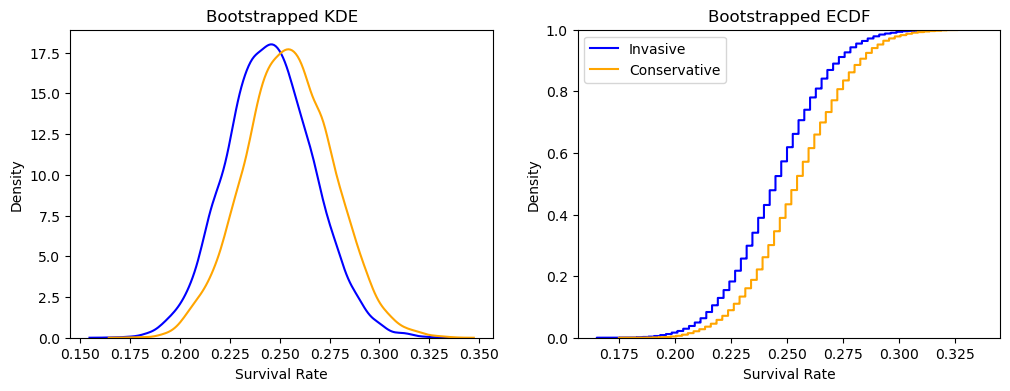

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

In the ECDF, the survival rate for the invasive treatment is less at every single density, suggesting that it isn't the best life-saving treatment. In the KDE there is a fairly significant overlap between invasive/conservative, with the invasive curve being centered a little bit to the left (lower survival rate) than the conservative treatment. 

**4.** Make a plot of the KDE and ECDF for the ATE. 

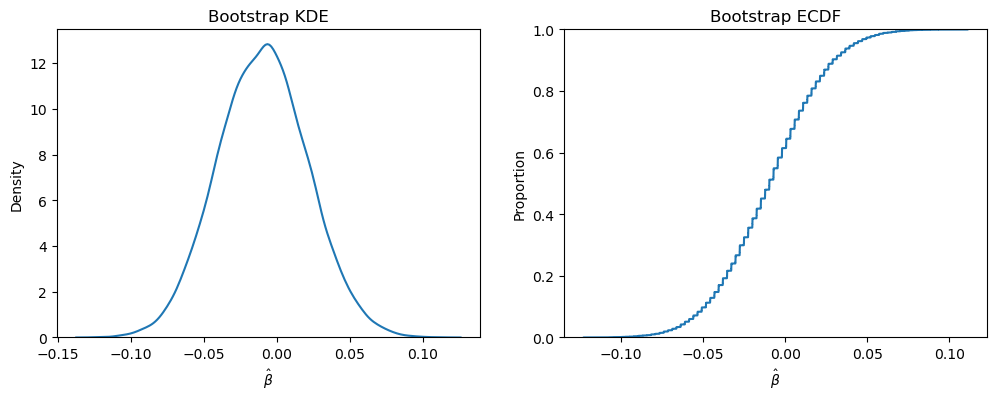

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06108082  0.04181353]
95% CI: [-0.06886561  0.05209631]
99% CI: [-0.0894046   0.07018402]


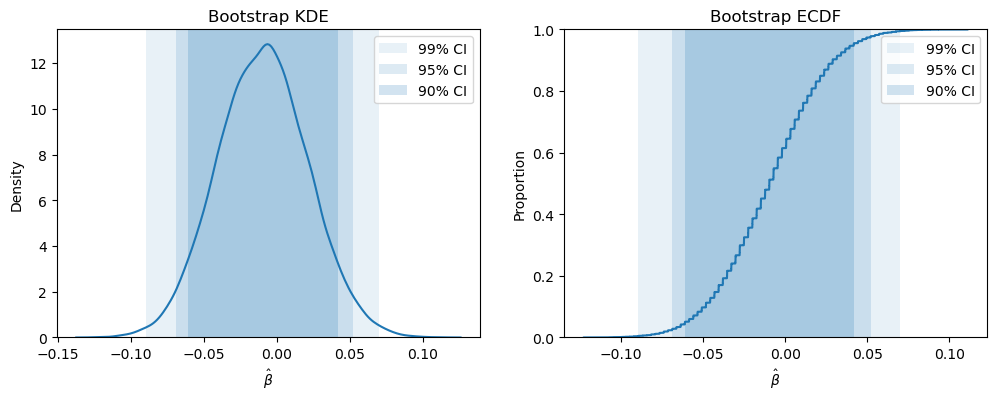

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

We fail to reject the null hypothesis that the ATE != 0 for all of the confidence intervals. At all levels, the intervals contain 0 so we cannot confidently conclude that there is a significant average treatment effect. 

**6.** What have we learned about inserting balloons into hearts?

We can't say much about the treatment since all confidence intervals and KDE's include zero, but we can say that the effect of the invasive treatment is definitely not positive. The density is shifted slightly to the left of zero, but it is not significant enough to draw any conclusions from it. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [8]:
diabetes = pd.read_csv('../data/diabetes.csv')
diabetes.head()

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [9]:
pd.crosstab(diabetes['treatment'], diabetes['outcome'])

outcome,failure,success
treatment,,
lifestyle,109,125
met,120,112
rosi,90,143


1) Metformin actually have a <50% success rate, while lifestyle changes and Rosiglitazone have a greater than 50% success rate (much higher for Rosiglitazone). In this sample, the treatments ordered by success rate (desc) are Rosi, Lifestyle, and Metformin.

In [10]:
df_met = diabetes.loc[diabetes['treatment'] == 'met', :]
df_rosi = diabetes.loc[diabetes['treatment'] == 'rosi', :]
df_lifestyle = diabetes.loc[diabetes['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

for t in range(R):
    
    df_mett = df_met.sample(frac=1.0, replace=True)
    df_rosit = df_rosi.sample(frac=1.0, replace=True)
    df_lifestylet = df_lifestyle.sample(frac=1.0, replace=True)
    
    omet = (df_mett['outcome'] == 'success').mean()
    orosi = (df_rosit['outcome'] == 'success').mean()
    olifestyle = (df_lifestylet['outcome'] == 'success').mean()
    
    outcome_met.append(omet)
    outcome_rosi.append(orosi)
    outcome_lifestyle.append(olifestyle)

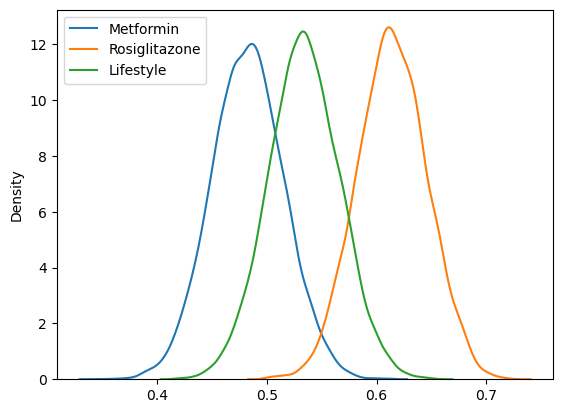

In [11]:
sns.kdeplot(outcome_met, label='Metformin')
sns.kdeplot(outcome_rosi, label='Rosiglitazone')
sns.kdeplot(outcome_lifestyle, label='Lifestyle')
plt.legend()

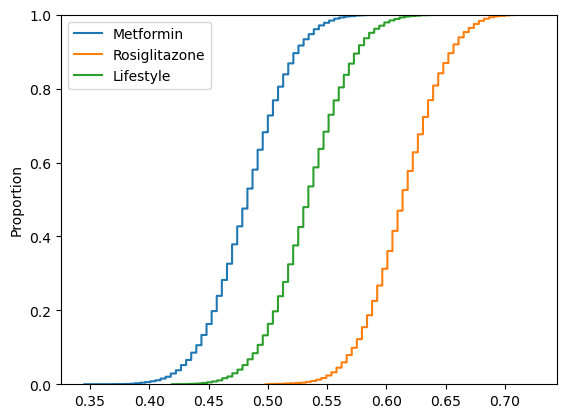

In [12]:
sns.ecdfplot(outcome_met, label='Metformin')
sns.ecdfplot(outcome_rosi, label='Rosiglitazone')
sns.ecdfplot(outcome_lifestyle, label='Lifestyle')
plt.legend()

3) The treatments all have fairly similar normal distributions in the KDE. In the ECDF, Rosiglitazone has a higher success rate at every percentile than the other two, and so do Lifestyle adjustments over Metformin. It suggests that Rosi is the best treatment, but we can't say for sure until we test it. 

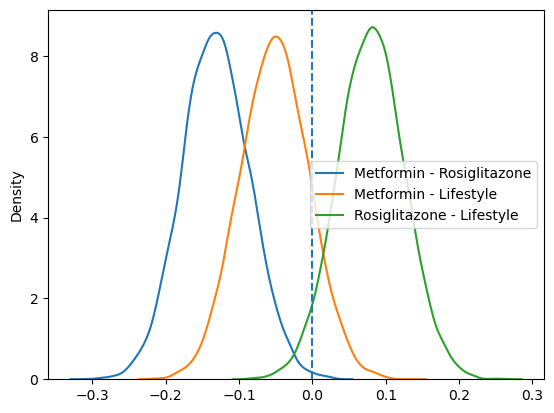

In [13]:
ate_met_rosi = np.array(outcome_met) - np.array(outcome_rosi)
ate_met_lifestyle = np.array(outcome_met) - np.array(outcome_lifestyle)
ate_rosi_lifestyle = np.array(outcome_rosi) - np.array(outcome_lifestyle)

sns.kdeplot(ate_met_rosi, label='Metformin - Rosiglitazone')
sns.kdeplot(ate_met_lifestyle, label='Metformin - Lifestyle')
sns.kdeplot(ate_rosi_lifestyle, label='Rosiglitazone - Lifestyle')
plt.axvline(0, linestyle='--')
plt.legend()

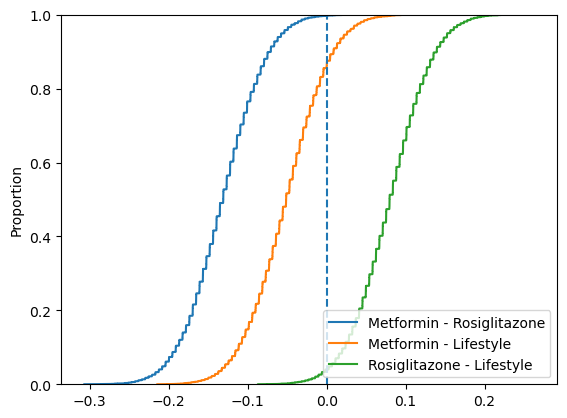

In [14]:
sns.ecdfplot(ate_met_rosi, label='Metformin - Rosiglitazone')
sns.ecdfplot(ate_met_lifestyle, label='Metformin - Lifestyle')
sns.ecdfplot(ate_rosi_lifestyle, label='Rosiglitazone - Lifestyle')

plt.axvline(0, linestyle='--')
plt.legend()

In [15]:
ci90_met_rosi = np.quantile(ate_met_rosi, [.05, .95])
ci90_met_lifestyle = np.quantile(ate_met_lifestyle, [.05, .95])
ci90_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.05, .95])

ci95_met_rosi = np.quantile(ate_met_rosi, [.025, .975])
ci95_met_lifestyle = np.quantile(ate_met_lifestyle, [.025, .975])
ci95_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.025, .975])

ci99_met_rosi = np.quantile(ate_met_rosi, [.005, .995])
ci99_met_lifestyle = np.quantile(ate_met_lifestyle, [.005, .995])
ci99_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.005, .995])

print('Met - Rosi')
print('90% CI:', ci90_met_rosi)
print('95% CI:', ci95_met_rosi)
print('99% CI:', ci99_met_rosi)

print('\nMet - Lifestyle')
print('90% CI:', ci90_met_lifestyle)
print('95% CI:', ci95_met_lifestyle)
print('99% CI:', ci99_met_lifestyle)

print('\nRosi - Lifestyle')
print('90% CI:', ci90_rosi_lifestyle)
print('95% CI:', ci95_rosi_lifestyle)
print('99% CI:', ci99_rosi_lifestyle)

Met - Rosi
90% CI: [-0.20421415 -0.05370264]
95% CI: [-0.221197   -0.04060604]
99% CI: [-0.2471696  -0.01054462]

Met - Lifestyle
90% CI: [-0.12864721  0.02578839]
95% CI: [-0.14161509  0.03894047]
99% CI: [-0.17141947  0.06889202]

Rosi - Lifestyle
90% CI: [0.00665786 0.15636165]
95% CI: [-0.01030822  0.16949121]
99% CI: [-0.04029566  0.19537233]


We reject the null hypothesis only for the average treatment effect between Rosiglitazone and Metformin, at a 90, 95, and 99 percent level. There is not enough evidence to suggest a significant ATE between lifestyle-metformin but rosiglitazone-lifestyle does have a significant ATE at the 90 percent level. Rosiglitazone seems to be the most effective treatment for pre-diabetics. 

Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [16]:
# Table 1. Observed outcomes by treatment

outcome_counts = pd.crosstab(diabetes["treatment"], diabetes["outcome"])
outcome_counts = outcome_counts.reindex(["met", "rosi", "lifestyle"], fill_value=0)
outcome_counts = outcome_counts.reindex(columns=["success", "failure"], fill_value=0)
outcome_counts["Total"] = outcome_counts["success"] + outcome_counts["failure"]
outcome_counts["Success rate"] = outcome_counts["success"] / outcome_counts["Total"]

summary_table = outcome_counts[["success", "failure", "Total", "Success rate"]].rename(
    index={"met": "Metformin", "rosi": "Rosiglitazone", "lifestyle": "Lifestyle changes"},
    columns={"success": "Successes", "failure": "Failures"}
)
summary_display = summary_table.copy()
summary_display["Success rate"] = summary_display["Success rate"].map(lambda x: f"{x:.1%}")
display(summary_display)

# The observed success proportions are used below to calculate point estimates.
success_rates = {
    treatment: (diabetes.loc[diabetes["treatment"] == treatment, "outcome"] == "success").mean()
    for treatment in ["met", "rosi", "lifestyle"]
}

outcome,Successes,Failures,Total,Success rate
treatment,,,,
Metformin,112,120,232,48.3%
Rosiglitazone,143,90,233,61.4%
Lifestyle changes,125,109,234,53.4%


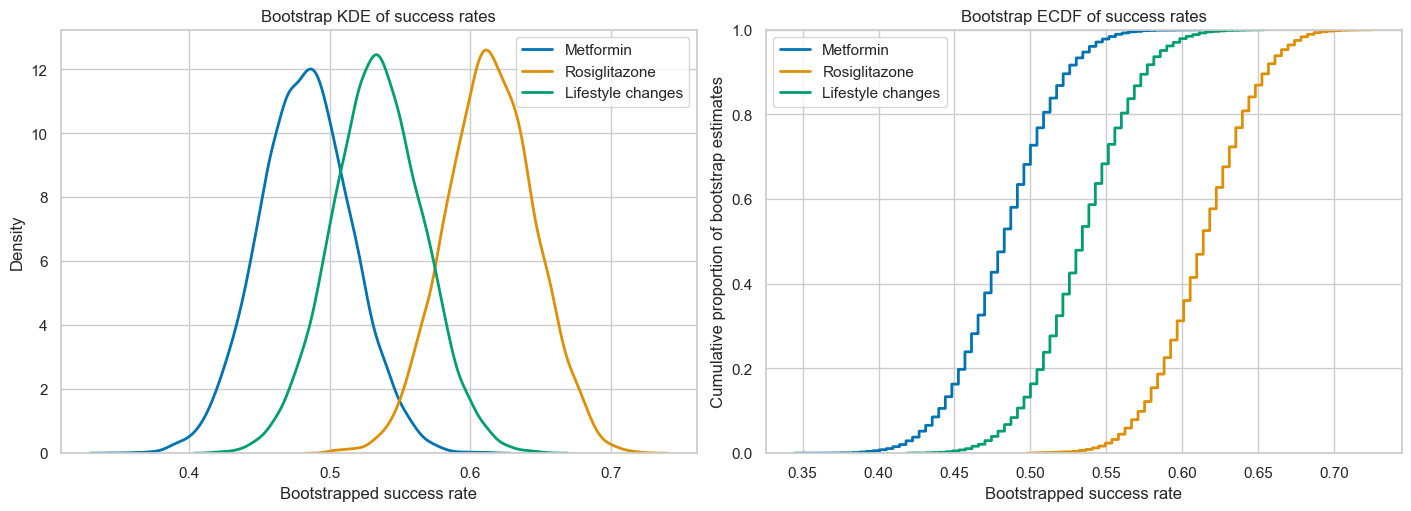

In [20]:
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
outcome_bootstraps = [(outcome_met, "Metformin"),(outcome_rosi, "Rosiglitazone"),(outcome_lifestyle, "Lifestyle changes"),]

for (estimates, label), color in zip(outcome_bootstraps, treatment_colors):
    sns.kdeplot(x=np.asarray(estimates), label=label, ax=axes[0], linewidth=2, color=color)
    sns.ecdfplot(x=np.asarray(estimates), label=label, ax=axes[1], linewidth=2, color=color)

axes[0].set_title("Bootstrap KDE of success rates")
axes[0].set_xlabel("Bootstrapped success rate")
axes[0].legend()

axes[1].set_title("Bootstrap ECDF of success rates")
axes[1].set_xlabel("Bootstrapped success rate")
axes[1].set_ylabel("Cumulative proportion of bootstrap estimates")
axes[1].legend()

plt.show()

In [22]:
pairwise_specs = [
    ("Metformin − Rosiglitazone", "met", "rosi", np.asarray(outcome_met) - np.asarray(outcome_rosi)),
    ("Metformin − Lifestyle changes", "met", "lifestyle", np.asarray(outcome_met) - np.asarray(outcome_lifestyle)),
    ("Rosiglitazone − Lifestyle changes", "rosi", "lifestyle", np.asarray(outcome_rosi) - np.asarray(outcome_lifestyle)),
]

pairwise_results = []
for label, first, second, boot_ate in pairwise_specs:
    pairwise_results.append({
        "comparison": label,
        "estimate": success_rates[first] - success_rates[second],
        "bootstrap": boot_ate,
        "ci90": np.quantile(boot_ate, [0.05, 0.95]),
        "ci95": np.quantile(boot_ate, [0.025, 0.975]),
        "ci99": np.quantile(boot_ate, [0.005, 0.995]),
    })

def format_ci(ci):
    return f"[{ci[0] * 100:.1f}, {ci[1] * 100:.1f}]"

effect_table = pd.DataFrame([
    {
        "Comparison (first − second)": result["comparison"],
        "Observed ATE (percentage points)": 100 * result["estimate"],
        "90% CI": format_ci(result["ci90"]),
        "95% CI": format_ci(result["ci95"]),
        "99% CI": format_ci(result["ci99"]),
    }
    for result in pairwise_results
])
effect_table["Observed ATE (percentage points)"] = effect_table["Observed ATE (percentage points)"].map(lambda x: f"{x:.1f}")
effect_table

,Comparison (first − second),Observed ATE (percentage points),90% CI,95% CI,99% CI
0,Metformin − Rosiglitazone,-13.1,"[-20.4, -5.4]","[-22.1, -4.1]","[-24.7, -1.1]"
1,Metformin − Lifestyle changes,-5.1,"[-12.9, 2.6]","[-14.2, 3.9]","[-17.1, 6.9]"
2,Rosiglitazone − Lifestyle changes,8.0,"[0.7, 15.6]","[-1.0, 16.9]","[-4.0, 19.5]"


This trial compared metformin, rosiglitazone, and lifestyle changes using a binary outcome of success or failure on whether or not the treatment prevented diabetes among pre-diabetics. The trial included 232 participants in the metformin arm, 233 in the rosiglitazone arm, and 234 in the lifestyle arm. The first table summarizes the observed outcomes, while the first figure shows the bootstrap distributions of each arm's success rate. Since the treatments were randomly assigned, we can provide estimates of treatment effects.

Rosiglitazone had the highest success rate at 61.4%, followed by lifestyle changes at 53.4% and metformin at 48.3%. The difference was 13.1 percentage points in favor of rosiglitazone over metformin, 8.0 percentage points for rosiglitazone over lifestyle, and 5.1 percent in favor of lifestyle changes over metformin. 

The metformin minus rosiglitazone ATE had a 95% confidence interval of −22.1 to −4.1 percentage points. its 90%, 95%, and 99% intervals all exclude zero, indicating better success using rosiglitazone over metformin. The metformin minus lifestyle interval was −14.2 to 3.9 percentage points, which includes zero at all three confidence levels, so we can't infer a significant difference in teh treatment. The rosiglitazone minus lifestyle interval was −1.0 to 16.9 percentage points at 95%, which also includes zero. Its 90% interval, however, is 0.7 to 15.6 percentage points, so this comparison excludes zero at the 90% level but not at the 95% or 99% levels.

Overall, rosiglitazone appears to be the most promising treatment and performs better than metformin across all three reported confidence levels. The evidence that rosiglitazone is better than lifestyle changes is weaker, and we can't infer any significant difference in treatment between lifestyle changes and metformin. Therefore, the results support using rosiglitazone instead of metformin, but they do not establish a definitive overall recommendation between all three interventions.